In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Imports successful!")
print("PyTorch version:", torch.__version__)


Imports successful!
PyTorch version: 2.11.0+cpu


In [2]:

mnist_train = datasets.MNIST(
    root="/kaggle/working/data",
    train=True,
    download=True
)

mnist_test = datasets.MNIST(
    root="/kaggle/working/data",
    train=False,
    download=True
)

# Convert images and labels into NumPy arrays
train_x_all = mnist_train.data.numpy()
train_y_all = mnist_train.targets.numpy()

test_x = mnist_test.data.numpy()
test_y = mnist_test.targets.numpy()

# Binary labels: even = 0, odd = 1
train_y_all = (train_y_all % 2).astype(np.int64)
test_y = (test_y % 2).astype(np.int64)

# Split training data into train and validation sets
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(train_x_all))

split = int(0.8 * len(indices))
train_idx = indices[:split]
val_idx = indices[split:]

train_x = train_x_all[train_idx]
train_y = train_y_all[train_idx]

val_x = train_x_all[val_idx]
val_y = train_y_all[val_idx]

print("Training examples:", len(train_x))
print("Validation examples:", len(val_x))
print("Test examples:", len(test_x))
print("Binary classes:", np.unique(train_y))


100%|██████████| 9.91M/9.91M [00:00<00:00, 37.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.16MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.97MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.64MB/s]

Training examples: 48000
Validation examples: 12000
Test examples: 10000
Binary classes: [0 1]


In [3]:

def make_colored_mnist(images, labels, corr, seed=42):
    if not -1 <= corr <= 1:
        raise ValueError("corr must be between -1 and 1")

    rng = np.random.default_rng(seed)

    # Choose whether color agrees with the label
    matches = rng.random(len(labels)) < ((1 + corr) / 2)

    # Color bit: 0 = red, 1 = green
    color_bits = np.where(matches, labels, 1 - labels).astype(np.int64)

    # Normalize grayscale images to [0, 1]
    grayscale = images.astype(np.float32) / 255.0

    # Build RGB images: one active color channel
    colored = np.zeros(
        (len(images), 3, 28, 28),
        dtype=np.float32
    )

    red_mask = (color_bits == 0)
    green_mask = (color_bits == 1)

    colored[red_mask, 0, :, :] = grayscale[red_mask]
    colored[green_mask, 1, :, :] = grayscale[green_mask]

    return colored, color_bits

print("Colored MNIST generator defined!")


Colored MNIST generator defined!


In [4]:

train_images, train_colors = make_colored_mnist(
    train_x, train_y, corr=0.95, seed=101
)

val_images, val_colors = make_colored_mnist(
    val_x, val_y, corr=0.95, seed=102
)

train_labels = train_y
val_labels = val_y

print("Training image shape:", train_images.shape)
print("Validation image shape:", val_images.shape)
print("Training labels shape:", train_labels.shape)
print("Training colors shape:", train_colors.shape)


Training image shape: (48000, 3, 28, 28)
Validation image shape: (12000, 3, 28, 28)
Training labels shape: (48000,)
Training colors shape: (48000,)


In [5]:

test_correlations = [0.75, 0.50, 0.25, 0.00, -0.95]

ood_data = {}

for i, corr in enumerate(test_correlations):
    images, colors = make_colored_mnist(
        test_x,
        test_y,
        corr=corr,
        seed=200 + i
    )

    ood_data[corr] = (images, test_y.copy(), colors)

print("Test environments created:", list(ood_data.keys()))


Test environments created: [0.75, 0.5, 0.25, 0.0, -0.95]


In [6]:
def show_correlation(name, labels, colors):
    agreement = np.mean(labels == colors)
    observed_corr = np.corrcoef(labels, colors)[0, 1]

    print(f"{name}")
    print(f"  Color-label agreement: {agreement:.3f}")
    print(f"  Observed correlation:  {observed_corr:.3f}")

show_correlation("Training", train_labels, train_colors)

for corr, (_, labels, colors) in ood_data.items():
    show_correlation(f"Test target correlation = {corr}", labels, colors)

assert train_images.shape == (len(train_labels), 3, 28, 28)
assert train_images.dtype == np.float32
assert train_images.min() >= 0.0
assert train_images.max() <= 1.0

print("\nBasic data checks passed!")


Training
  Color-label agreement: 0.975
  Observed correlation:  0.950
Test target correlation = 0.75
  Color-label agreement: 0.882
  Observed correlation:  0.764
Test target correlation = 0.5
  Color-label agreement: 0.753
  Observed correlation:  0.506
Test target correlation = 0.25
  Color-label agreement: 0.620
  Observed correlation:  0.240
Test target correlation = 0.0
  Color-label agreement: 0.500
  Observed correlation:  0.001
Test target correlation = -0.95
  Color-label agreement: 0.025
  Observed correlation:  -0.950

Basic data checks passed!


In [7]:

def swap_red_green(images):
    swapped = images.copy()
    swapped[:, [0, 1], :, :] = images[:, [1, 0], :, :]
    return swapped

# Test on a small batch
sample = train_images[:100]
counterfactual = swap_red_green(sample)
recovered = swap_red_green(counterfactual)

print("Exact recovery:", np.array_equal(recovered, sample))

original_intensity = sample.sum(axis=1)
counterfactual_intensity = counterfactual.sum(axis=1)

print(
    "Per-pixel intensity preserved:",
    np.allclose(original_intensity, counterfactual_intensity)
)

print("Labels unchanged by intervention:", len(train_labels[:100]) == len(counterfactual))


Exact recovery: True
Per-pixel intensity preserved: True
Labels unchanged by intervention: True


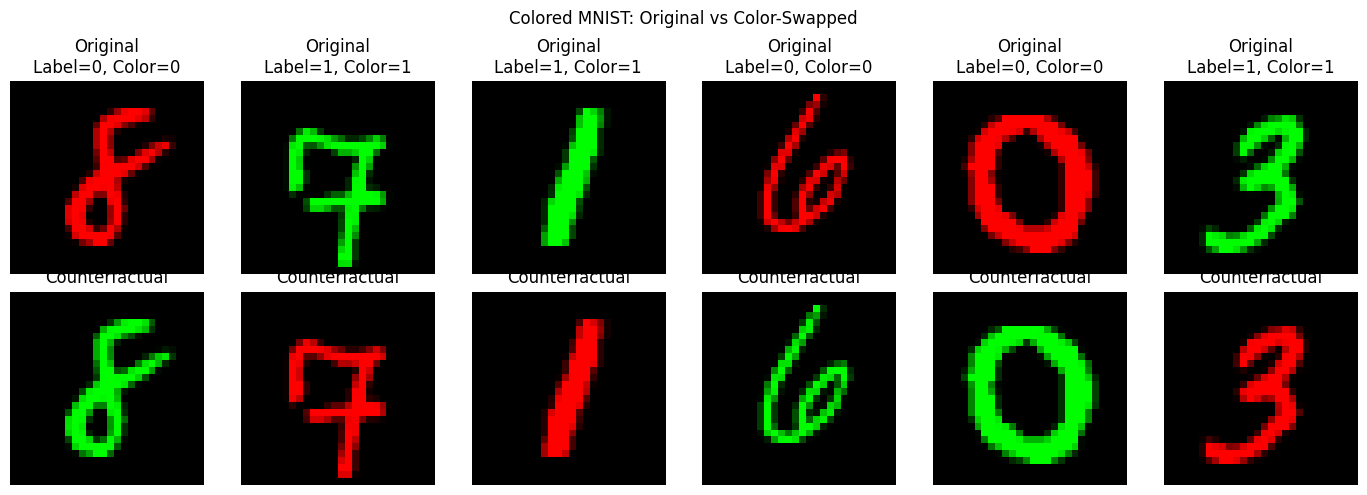

In [8]:

fig, axes = plt.subplots(2, 6, figsize=(14, 5))

for i in range(6):
    original = train_images[i]
    counterfactual = swap_red_green(original[None, ...])[0]

    axes[0, i].imshow(np.transpose(original, (1, 2, 0)))
    axes[0, i].set_title(
        f"Original\nLabel={train_labels[i]}, Color={train_colors[i]}"
    )

    axes[1, i].imshow(np.transpose(counterfactual, (1, 2, 0)))
    axes[1, i].set_title("Counterfactual")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.suptitle("Colored MNIST: Original vs Color-Swapped")
plt.tight_layout()
plt.show()


In [9]:

print("========== PART 1 + PART 2 CHECKPOINT ==========")
print("Training data:", train_images.shape)
print("Validation data:", val_images.shape)
print("Test environments:", len(ood_data))
print("Intervention reversibility:", np.array_equal(
    swap_red_green(swap_red_green(train_images[:10])),
    train_images[:10]
))
print("Ready for baseline modelling!")


========== PART 1 + PART 2 CHECKPOINT ==========
Training data: (48000, 3, 28, 28)
Validation data: (12000, 3, 28, 28)
Test environments: 5
Intervention reversibility: True
Ready for baseline modelling!


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# Flatten each image into a vector of 2,352 pixel features
X_train = train_images.reshape(len(train_images), -1)
X_val = val_images.reshape(len(val_images), -1)

# Train a simple baseline model
baseline = LogisticRegression(
    max_iter=300,
    solver="lbfgs"
)

baseline.fit(X_train, train_labels)

val_predictions = baseline.predict(X_val)
val_accuracy = accuracy_score(val_labels, val_predictions)

print(f"Validation accuracy: {val_accuracy:.4f}")

Validation accuracy: 0.9807


In [11]:
results = []

for corr, (images, labels, colors) in ood_data.items():
    X_test_env = images.reshape(len(images), -1)

    predictions = baseline.predict(X_test_env)
    accuracy = accuracy_score(labels, predictions)

    results.append({
        "Target correlation": corr,
        "Accuracy": accuracy
    })

for result in results:
    print(
        f"Target correlation: {result['Target correlation']:>5} | "
        f"Accuracy: {result['Accuracy']:.4f}"
    )

Target correlation:  0.75 | Accuracy: 0.9335
Target correlation:   0.5 | Accuracy: 0.8678
Target correlation:  0.25 | Accuracy: 0.7991
Target correlation:   0.0 | Accuracy: 0.7353
Target correlation: -0.95 | Accuracy: 0.4839


In [12]:
sample_images = test_x[:2000]
sample_labels = test_y[:2000]

# Create a test set with the training color relationship
sample_colored, sample_colors = make_colored_mnist(
    sample_images,
    sample_labels,
    corr=0.95,
    seed=777
)

sample_counterfactual = swap_red_green(sample_colored)

original_predictions = baseline.predict(
    sample_colored.reshape(len(sample_colored), -1)
)

counterfactual_predictions = baseline.predict(
    sample_counterfactual.reshape(len(sample_counterfactual), -1)
)

prediction_change_rate = np.mean(
    original_predictions != counterfactual_predictions
)

original_accuracy = accuracy_score(sample_labels, original_predictions)
counterfactual_accuracy = accuracy_score(
    sample_labels, counterfactual_predictions
)

print(f"Original accuracy: {original_accuracy:.4f}")
print(f"Counterfactual accuracy: {counterfactual_accuracy:.4f}")
print(f"Prediction change rate: {prediction_change_rate:.4f}")

Original accuracy: 0.9870
Counterfactual accuracy: 0.4815
Prediction change rate: 0.5265


In [13]:

# Model A: RGB images, including color and shape
X_rgb_train = train_images.reshape(len(train_images), -1)
X_rgb_val = val_images.reshape(len(val_images), -1)

# Model B: Color-only features
# The red and green channels are mutually exclusive in our generator.
# Mean red and green intensity identify the assigned color.
X_color_train = train_images[:, :2, :, :].mean(axis=(2, 3))
X_color_val = val_images[:, :2, :, :].mean(axis=(2, 3))

# Model C: Shape-only features
# Sum the RGB channels to recover the original grayscale digit.
X_shape_train = train_images.sum(axis=1).reshape(len(train_images), -1)
X_shape_val = val_images.sum(axis=1).reshape(len(val_images), -1)

print("RGB features:", X_rgb_train.shape)
print("Color-only features:", X_color_train.shape)
print("Shape-only features:", X_shape_train.shape)


RGB features: (48000, 2352)
Color-only features: (48000, 2)
Shape-only features: (48000, 784)


In [14]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

models = {
    "RGB": LogisticRegression(max_iter=300),
    "Color-only": LogisticRegression(max_iter=300),
    "Shape-only": LogisticRegression(max_iter=300)
}

feature_sets = {
    "RGB": (X_rgb_train, X_rgb_val),
    "Color-only": (X_color_train, X_color_val),
    "Shape-only": (X_shape_train, X_shape_val)
}

for name, model in models.items():
    X_train_model, X_val_model = feature_sets[name]

    model.fit(X_train_model, train_labels)

    val_predictions = model.predict(X_val_model)
    accuracy = accuracy_score(val_labels, val_predictions)

    print(f"{name:12s} validation accuracy: {accuracy:.4f}")


RGB          validation accuracy: 0.9807
Color-only   validation accuracy: 0.9739
Shape-only   validation accuracy: 0.8975


In [15]:

from sklearn.metrics import accuracy_score

ood_results = []

for corr, (images, labels, colors) in ood_data.items():

    # RGB representation
    X_rgb = images.reshape(len(images), -1)

    # Color-only representation
    X_color = images[:, :2, :, :].mean(axis=(2, 3))

    # Shape-only representation
    X_shape = images.sum(axis=1).reshape(len(images), -1)

    test_features = {
        "RGB": X_rgb,
        "Color-only": X_color,
        "Shape-only": X_shape
    }

    row = {"Target correlation": corr}

    for name, model in models.items():
        predictions = model.predict(test_features[name])
        row[name] = accuracy_score(labels, predictions)

    ood_results.append(row)

for row in ood_results:
    print(
        f"corr={row['Target correlation']:>5}: "
        f"RGB={row['RGB']:.4f}, "
        f"Color-only={row['Color-only']:.4f}, "
        f"Shape-only={row['Shape-only']:.4f}"
    )


corr= 0.75: RGB=0.9335, Color-only=0.8827, Shape-only=0.9008
corr=  0.5: RGB=0.8678, Color-only=0.7539, Shape-only=0.9008
corr= 0.25: RGB=0.7991, Color-only=0.6208, Shape-only=0.9008
corr=  0.0: RGB=0.7353, Color-only=0.5022, Shape-only=0.9008
corr=-0.95: RGB=0.4839, Color-only=0.0283, Shape-only=0.9008


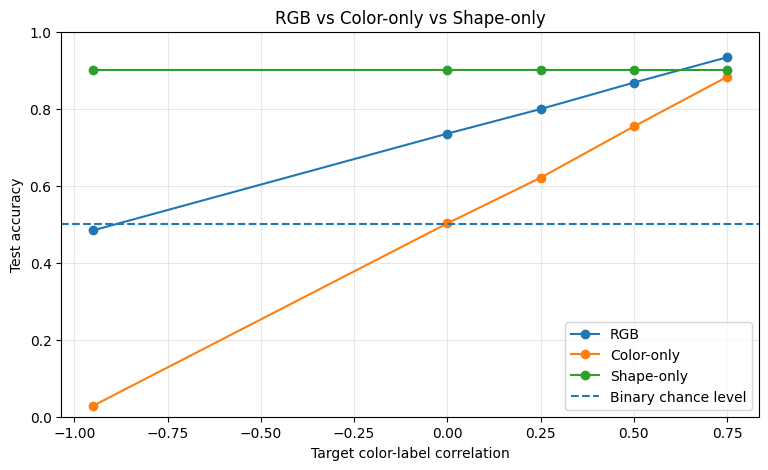

In [16]:

import matplotlib.pyplot as plt

correlations = [row["Target correlation"] for row in ood_results]

plt.figure(figsize=(9, 5))

for name in ["RGB", "Color-only", "Shape-only"]:
    accuracies = [row[name] for row in ood_results]
    plt.plot(correlations, accuracies, marker="o", label=name)

plt.axhline(0.5, linestyle="--", label="Binary chance level")
plt.xlabel("Target color-label correlation")
plt.ylabel("Test accuracy")
plt.title("RGB vs Color-only vs Shape-only")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Use only the color identity, not the image pixels
X_color_train_strict = train_colors.reshape(-1, 1)
X_color_val_strict = val_colors.reshape(-1, 1)

strict_color_model = LogisticRegression()
strict_color_model.fit(X_color_train_strict, train_labels)

val_pred = strict_color_model.predict(X_color_val_strict)

print(
    "Strict color-only validation accuracy:",
    round(accuracy_score(val_labels, val_pred), 4)
)


Strict color-only validation accuracy: 0.9738


In [18]:

strict_color_results = []

for corr, (images, labels, colors) in ood_data.items():
    predictions = strict_color_model.predict(colors.reshape(-1, 1))
    accuracy = accuracy_score(labels, predictions)

    strict_color_results.append({
        "correlation": corr,
        "accuracy": accuracy
    })

for result in strict_color_results:
    print(
        f"corr={result['correlation']:>5}: "
        f"strict color-only accuracy={result['accuracy']:.4f}"
    )


corr= 0.75: strict color-only accuracy=0.8822
corr=  0.5: strict color-only accuracy=0.7532
corr= 0.25: strict color-only accuracy=0.6197
corr=  0.0: strict color-only accuracy=0.5005
corr=-0.95: strict color-only accuracy=0.0252


In [19]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, mutual_info_score
from itertools import combinations
from math import factorial
import pandas as pd

ATTRS = ["color", "marker_tl", "marker_br"]
PATCH = {"marker_tl": (slice(1, 4), slice(1, 4)),     # top-left 3x3
         "marker_br": (slice(24, 27), slice(24, 27))} # bottom-right 3x3

def make_multi_attr_mnist(images, labels, corrs, seed=0):
    """corrs: dict attr -> label correlation (0 = independent decoy)."""
    rng = np.random.default_rng(seed)
    gray = images.astype(np.float32) / 255.0
    n = len(labels)
    out = np.zeros((n, 3, 28, 28), dtype=np.float32)
    attrs = {}
    for a in ATTRS:
        c = corrs.get(a, 0.0)
        match = rng.random(n) < (1 + c) / 2
        attrs[a] = np.where(match, labels, 1 - labels).astype(np.int64)
    out[attrs["color"] == 0, 0] = gray[attrs["color"] == 0]   # red
    out[attrs["color"] == 1, 1] = gray[attrs["color"] == 1]   # green
    for a, (r, c) in PATCH.items():                           # markers: blue channel only
        out[attrs[a] == 1, 2, r, c] = 1.0
    return out, attrs


In [20]:
def intervene(images, attr):
    x = images.copy()
    if attr == "color":
        x[:, [0, 1]] = images[:, [1, 0]]                 # swap red/green
    elif attr in PATCH:
        r, c = PATCH[attr]
        x[:, 2, r, c] = 1.0 - images[:, 2, r, c]         # toggle marker on/off
    elif attr == "null":
        pass                                             # do-nothing control
    else:
        raise ValueError(attr)
    return x

In [21]:
def build_registry(labels, attrs, threshold=0.5, design_corrs=None):
    """
    Register spuriousness from the experiment design, not noisy sample correlation.
    Convention: strictly greater than threshold is spurious; exactly threshold is not.
    Observed sample correlations are retained as diagnostics.
    """
    reg = {}
    for a, v in attrs.items():
        observed = float(np.corrcoef(labels, v)[0, 1])
        designed = float(design_corrs[a]) if design_corrs is not None and a in design_corrs else observed
        reg[a] = {
            "train_corr": observed,
            "design_corr": designed,
            "spurious": abs(designed) > threshold
        }
    return reg

flat = lambda x: x.reshape(len(x), -1)


In [22]:
def sensitivity_score(model, X, attr):
    """Main score (Person 2's job): fraction of predictions that flip."""
    p0 = model.predict(flat(X))
    p1 = model.predict(flat(intervene(X, attr)))
    return float(np.mean(p0 != p1))

def label_corr_score(labels, attrs, attr):
    """Data-only baseline."""
    return abs(float(np.corrcoef(labels, attrs[attr])[0, 1]))

def mutual_information_score(labels, attrs, attr):
    """Data-only baseline: mutual information between training labels and a
    training attribute (discrete, computed on E1 training data)."""
    return float(mutual_info_score(np.asarray(labels).astype(int),
                                   np.asarray(attrs[attr]).astype(int)))

def grouped_attribute_permutation_score(model, X, y, attr_values, attr,
                                        n_repeats=5, seed=12345):
    """Grouped permutation importance on held-out validation data.
    Shuffle one attribute across examples, rebuild that attribute in the images,
    and measure the accuracy drop.  Score = baseline acc - mean permuted acc.
    (Different from intervene(), which toggles the attribute within each example.)"""
    X = np.asarray(X); y = np.asarray(y)
    current = np.asarray(attr_values).astype(np.int64)
    if not (len(X) == len(y) == len(current)):
        raise ValueError("X, y and attr_values must have equal lengths.")
    if attr != "color" and attr not in PATCH:
        raise ValueError(f"Unknown attribute: {attr}")
    baseline_acc = accuracy_score(y, model.predict(flat(X)))
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(n_repeats):
        shuffled = rng.permutation(current)
        X_perm = X.copy()
        if attr == "color":
            changed = shuffled != current            # swap R/G only where assigned colour changed
            X_perm[changed, 0] = X[changed, 1]
            X_perm[changed, 1] = X[changed, 0]
        else:
            r, c = PATCH[attr]                       # rebuild marker from shuffled values
            X_perm[:, 2, r, c] = shuffled[:, None, None].astype(X_perm.dtype)
        drops.append(baseline_acc - accuracy_score(y, model.predict(flat(X_perm))))
    return float(np.mean(drops))


In [23]:
def stability_score(model, X, y, attrs, attr):
    pred = model.predict(flat(X))
    agree = attrs[attr] == y
    if agree.sum() < 20 or (~agree).sum() < 20:
        return np.nan                     # too few samples in one group
    return float(accuracy_score(y[agree], pred[agree])
                 - accuracy_score(y[~agree], pred[~agree]))

In [24]:
def attribute_shapley(model, X, y, attr_list):
    k = len(attr_list)
    def value(S):
        x = X
        for a in S:
            x = intervene(x, a)
        proba = model.predict_proba(flat(x))
        return proba[np.arange(len(y)), y]          # P(true class)
    cache = {frozenset(S): value(S)
             for r in range(k + 1) for S in combinations(attr_list, r)}
    phi = {}
    for a in attr_list:
        others = [b for b in attr_list if b != a]
        tot = np.zeros(len(y))
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for S in combinations(others, r):
                tot += w * (cache[frozenset(S)] - cache[frozenset(S) | {a}])
        phi[a] = float(np.mean(np.abs(tot)))
    return phi

In [25]:
def run_task(task_id, model_fn, n_score=2000):
    rng = np.random.default_rng(1000 + task_id)
    order = rng.permutation(ATTRS)
    corrs = {order[0]: 0.9, order[1]: 0.6, order[2]: 0.0}   # strong, weak, decoy

    Xtr, Atr = make_multi_attr_mnist(train_x, train_y, corrs, seed=2000 + task_id)
    Xva, Ava = make_multi_attr_mnist(val_x,   val_y,   corrs, seed=3000 + task_id)
    reg = build_registry(train_y, Atr, threshold=0.5, design_corrs=corrs)

    model = model_fn().fit(flat(Xtr), train_y)
    Xs, ys = Xva[:n_score], val_y[:n_score]
    As = {a: v[:n_score] for a, v in Ava.items()}
    shap = attribute_shapley(model, Xs, ys, ATTRS)

    rows = []
    for a in ATTRS:
        rows.append({
            "task": task_id, "attr": a, "true_corr": corrs[a],
            "spurious": reg[a]["spurious"],
            "sensitivity": sensitivity_score(model, Xs, a),
            "label_corr":  label_corr_score(train_y, Atr, a),
            "stability":   stability_score(model, Xs, ys, As, a),
            "shap":        shap[a],
            "mutual_info": mutual_information_score(train_y, Atr, a),
            "permutation_importance": grouped_attribute_permutation_score(
                model, Xs, ys, As[a], a, n_repeats=5, seed=12345),
        })
    null = sensitivity_score(model, Xs, "null")
    return rows, order[0], null

def evaluate(all_rows, strongest,
             methods=("sensitivity", "label_corr", "stability", "shap",
                      "mutual_info", "permutation_importance")):
    df = pd.DataFrame(all_rows)
    out = {}
    for m in methods:
        top1 = np.mean([df[df.task == t].sort_values(m, ascending=False).attr.iloc[0] == s
                        for t, s in strongest.items()])
        sub = df.dropna(subset=[m])
        auroc = roc_auc_score(sub.spurious, sub[m]) if sub.spurious.nunique() == 2 else np.nan
        out[m] = {"top1": top1, "auroc": auroc}
    return df, pd.DataFrame(out).T

In [26]:
lr = lambda: LogisticRegression(max_iter=300)
rows, strongest = [], {}
for t in range(10):                      # more tasks = more credible
    r, s, null = run_task(t, lr)
    rows += r; strongest[t] = s
    print(f"task {t}: shortcut = {s}, null sensitivity = {null:.3f}")

df, summary = evaluate(rows, strongest)
print(summary)
df.to_csv("/kaggle/working/blind_detection_lr.csv", index=False)

task 0: shortcut = color, null sensitivity = 0.000
task 1: shortcut = marker_br, null sensitivity = 0.000
task 2: shortcut = color, null sensitivity = 0.000
task 3: shortcut = marker_br, null sensitivity = 0.000
task 4: shortcut = color, null sensitivity = 0.000
task 5: shortcut = color, null sensitivity = 0.000
task 6: shortcut = marker_br, null sensitivity = 0.000
task 7: shortcut = marker_br, null sensitivity = 0.000
task 8: shortcut = marker_tl, null sensitivity = 0.000
task 9: shortcut = marker_br, null sensitivity = 0.000
                        top1  auroc
sensitivity              1.0    1.0
label_corr               1.0    1.0
stability                1.0    1.0
shap                     1.0    1.0
mutual_info              1.0    1.0
permutation_importance   1.0    1.0


In [27]:
#  CONFIG 
import os, json, time, hashlib, itertools, pickle, shutil, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, t as t_dist
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./working")

CONFIG = {
    "out_dir": f"{WORK}/runs_mi_perm_v2",  # fresh dir: v1 used an intervention flip, not a true permutation
    # ---- experiment grid (cut down to what the team can finish) ----
    "grid": {
        "arch":       ["lr"],                    # Stage B: add "rf", "mlp", "cnn"
        "train_corr": [0.5, 0.7, 0.85, 0.95],
        "size":       [5000, 20000],
        "seed":       [0, 1, 2, 3, 4],
        "reg":        ["default"],               # stretch: ["low", "default", "high"]
        "aug":        ["none"],                  # stretch: ["none", "color_rand"]
    },
    "shortcut":    "color",                      # attribute whose correlation is swept
    "decoy_corrs": {"marker_tl": 0.0, "marker_br": 0.0},   # label-independent decoys
    "aug_p":       0.5,                          # fraction of train images colour-swapped under "color_rand"
    # ---- OOD environments (colour-label correlation at test time) ----
    "ood_envs":    {"E2": 0.75, "E3": 0.50, "E4": 0.25, "E5": 0.00, "REV": -0.95},
    # ---- scoring ----
    "n_score":     2000,                         # held-out val samples used for scoring
    "spurious_threshold": 0.5,
    "methods":     ["sensitivity", "label_corr", "stability", "shap",
                    "mutual_info", "permutation_importance"],
    # ---- analysis ----
    "target":      "rev_drop",                   # also: "mean_drop", "worst_drop"
    "cluster_by":  "seed",                       # cluster bootstrap unit
    "n_boot":      2000,
    "alpha":       0.05,
}

RESULT_COLS = ["run_id", "model", "seed", "size", "corr", "reg", "aug",
               "method", "feature", "score", "spurious"]

def read_scores(path):
    # keep the literal feature name "null" (pandas would otherwise read it as NaN)
    return pd.read_csv(path, keep_default_na=False, na_values=[""])

def paths(cfg):
    d = cfg["out_dir"]
    return {
        "dir": d,
        "models":   f"{d}/models",
        "partial":  f"{d}/partial",
        "meta":     f"{d}/run_meta.csv",
        "frozen":   f"{d}/scores_frozen.csv",
        "manifest": f"{d}/scores_frozen.manifest.json",
        "ood_long": f"{d}/ood_drops_long.csv",
        "ood_wide": f"{d}/ood_drops.csv",
        "analysis": f"{d}/analysis_spearman.csv",
    }

def grid_runs(cfg):
    g = cfg["grid"]
    keys = ["arch", "train_corr", "size", "seed", "reg", "aug"]
    return [dict(zip(keys, v)) for v in itertools.product(*[g[k] for k in keys])]

def run_id_of(r):
    return f"{r['arch']}_c{r['train_corr']}_n{r['size']}_s{r['seed']}_r{r['reg']}_a{r['aug']}"

print(f"Output dir: {CONFIG['out_dir']}")
print(f"Grid size:  {len(grid_runs(CONFIG))} runs")

Output dir: /kaggle/working/runs_mi_perm_v2
Grid size:  40 runs


In [28]:
# MODEL FACTORY 
# All models take FLAT inputs (N, 3*28*28) because the shared score functions call
# model.predict(flat(X)). A CNN wrapper (Stage B) must reshape inside and have
# fit / predict / predict_proba, then be added to MODEL_REGISTRY.
MODEL_REGISTRY = {}

REG_LEVELS = {
    "lr":  {"low": 10.0, "default": 1.0,  "high": 0.01},   # C
    "rf":  {"low": None, "default": 12,   "high": 6},      # max_depth
    "mlp": {"low": 1e-5, "default": 1e-4, "high": 1e-2},   # L2 alpha
}

def make_model(arch, reg="default", seed=0):
    if arch in MODEL_REGISTRY:
        return MODEL_REGISTRY[arch](reg=reg, seed=seed)
    if arch == "lr":
        return LogisticRegression(C=REG_LEVELS["lr"][reg], max_iter=300)
    if arch == "rf":
        return RandomForestClassifier(n_estimators=200, max_depth=REG_LEVELS["rf"][reg],
                                      n_jobs=-1, random_state=seed)
    if arch == "mlp":
        return MLPClassifier(hidden_layer_sizes=(256,), alpha=REG_LEVELS["mlp"][reg],
                             max_iter=50, early_stopping=True, random_state=seed)
    raise ValueError(f"Unknown arch '{arch}'. Register it in MODEL_REGISTRY.")

In [29]:
# RUN DRIVER (pre-shift only: never touches test_x)
def _shap_cached(ctx, attr):
    if "_shap" not in ctx:
        ctx["_shap"] = attribute_shapley(ctx["model"], ctx["Xs"], ctx["ys"], ATTRS)
    return ctx["_shap"][attr]

# Every score method has the same shape: fn(ctx, attr) -> number.
# To add a new method (e.g. mutual information), just add it here.
SCORE_FNS = {
    "sensitivity": lambda ctx, a: sensitivity_score(ctx["model"], ctx["Xs"], a),
    "label_corr":  lambda ctx, a: label_corr_score(ctx["ytr"], ctx["Atr"], a),
    "stability":   lambda ctx, a: stability_score(ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"], a),
    "shap":        _shap_cached,
    "mutual_info": lambda ctx, a: mutual_information_score(ctx["ytr"], ctx["Atr"], a),
    "permutation_importance": lambda ctx, a: grouped_attribute_permutation_score(
        ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"][a], a,
        n_repeats=5, seed=12345),
}

def make_e1(cfg, train_corr, size, seed, aug):
    """Training environment E1 (+ held-out val). Uses train_x / val_x only."""
    corrs = {cfg["shortcut"]: train_corr, **cfg["decoy_corrs"]}
    rng = np.random.default_rng(10_000 + seed)
    idx = rng.choice(len(train_y), size=min(size, len(train_y)), replace=False)
    Xtr, Atr = make_multi_attr_mnist(train_x[idx], train_y[idx], corrs, seed=20_000 + seed)
    ytr = train_y[idx]

    if aug == "color_rand":                     # colour randomisation augmentation
        flip = np.random.default_rng(30_000 + seed).random(len(ytr)) < cfg["aug_p"]
        Xtr[flip] = intervene(Xtr[flip], "color")
        Atr["color"] = np.where(flip, 1 - Atr["color"], Atr["color"])
    elif aug != "none":
        raise ValueError(aug)

    Xva, Ava = make_multi_attr_mnist(val_x, val_y, corrs, seed=40_000 + seed)
    return Xtr, ytr, Atr, Xva, val_y, Ava

def run_one(cfg, r):
    P = paths(cfg)
    rid = run_id_of(r)
    Xtr, ytr, Atr, Xva, yva, Ava = make_e1(cfg, r["train_corr"], r["size"], r["seed"], r["aug"])
    design_corrs = {cfg["shortcut"]: r["train_corr"], **cfg["decoy_corrs"]}
    if r["aug"] == "color_rand":
        # Randomly swapping a fraction p attenuates designed correlation by (1 - 2p).
        design_corrs[cfg["shortcut"]] *= (1.0 - 2.0 * cfg["aug_p"])
    reg = build_registry(ytr, Atr, threshold=cfg["spurious_threshold"],
                         design_corrs=design_corrs)

    t0 = time.time()
    model = make_model(r["arch"], r["reg"], r["seed"]).fit(flat(Xtr), ytr)
    fit_s = time.time() - t0

    n = cfg["n_score"]
    ctx = {"model": model, "Xs": Xva[:n], "ys": yva[:n],
           "As": {a: v[:n] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}

    base = {"run_id": rid, "model": r["arch"], "seed": r["seed"], "size": r["size"],
            "corr": r["train_corr"], "reg": r["reg"], "aug": r["aug"]}
    rows = []
    for m in cfg["methods"]:
        for a in ATTRS:
            rows.append({**base, "method": m, "feature": a,
                         "score": SCORE_FNS[m](ctx, a), "spurious": reg[a]["spurious"]})
    # null control: a do-nothing intervention should score 0
    rows.append({**base, "method": "sensitivity", "feature": "null",
                 "score": sensitivity_score(model, ctx["Xs"], "null"), "spurious": False})

    meta = {**base,
            "train_acc": accuracy_score(ytr, model.predict(flat(Xtr))),
            "id_val_acc": accuracy_score(yva, model.predict(flat(Xva))),
            "fit_seconds": round(fit_s, 2),
            "model_path": f"{P['models']}/{rid}.pkl"}
    for a in ATTRS:
        meta[f"traincorr_{a}"] = reg[a]["train_corr"]

    with open(meta["model_path"], "wb") as f:
        pickle.dump(model, f)
    pd.DataFrame(rows, columns=RESULT_COLS).to_csv(f"{P['partial']}/{rid}.csv", index=False)
    pd.DataFrame([meta]).to_csv(f"{P['partial']}/{rid}.meta.csv", index=False)
    return rows, meta

def run_grid(cfg, shard=(0, 1), verbose=True):
    """Runs every grid setting not already done. shard=(i, k) runs every k-th one starting at i,
    so a long grid can be split across several Kaggle versions."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise RuntimeError("Scores are already frozen; start a new out_dir for a new grid.")
    os.makedirs(P["models"], exist_ok=True); os.makedirs(P["partial"], exist_ok=True)
    runs = grid_runs(cfg)[shard[0]::shard[1]]
    for i, r in enumerate(runs):
        rid = run_id_of(r)
        if os.path.exists(f"{P['partial']}/{rid}.csv"):
            if verbose: print(f"[{i+1}/{len(runs)}] skip (done) {rid}")
            continue
        t0 = time.time()
        rows, meta = run_one(cfg, r)
        if verbose:
            s = {(x["method"], x["feature"]): x["score"] for x in rows}
            print(f"[{i+1}/{len(runs)}] {rid}  id_acc={meta['id_val_acc']:.3f}  "
                  f"sens(color)={s[('sensitivity','color')]:.3f}  "
                  f"sens(null)={s[('sensitivity','null')]:.3f}  ({time.time()-t0:.1f}s)")

In [30]:
# FREEZE WRITER
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def freeze_scores(cfg):
    """Merge all score files into scores_frozen.csv. Refuses to overwrite."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise FileExistsError(f"{P['frozen']} is frozen and will not be overwritten.")
    expected = {run_id_of(r) for r in grid_runs(cfg)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    missing = expected - done
    if missing:
        raise RuntimeError(f"{len(missing)} runs missing, e.g. {sorted(missing)[:3]}. Finish the grid first.")

    scores = pd.concat([read_scores(f"{P['partial']}/{r}.csv") for r in sorted(expected)], ignore_index=True)
    meta = pd.concat([pd.read_csv(f"{P['partial']}/{r}.meta.csv") for r in sorted(expected)], ignore_index=True)
    assert list(scores.columns) == RESULT_COLS, "results schema drifted"

    scores.to_csv(P["frozen"], index=False)
    meta.to_csv(P["meta"], index=False)
    manifest = {"sha256": _sha256(P["frozen"]), "meta_sha256": _sha256(P["meta"]),
                "n_rows": len(scores), "n_runs": len(expected),
                "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "config": cfg}
    with open(P["manifest"], "w") as f:
        json.dump(manifest, f, indent=2, default=str)
    for p in (P["frozen"], P["meta"], P["manifest"]):
        os.chmod(p, 0o444)
    print(f"Frozen {len(scores)} score rows from {len(expected)} runs -> {P['frozen']}")
    print(f"sha256 = {manifest['sha256']}")
    return manifest

In [31]:
#  OOD EVALUATION
def verify_freeze(cfg):
    P = paths(cfg)
    if not (os.path.exists(P["frozen"]) and os.path.exists(P["manifest"])):
        raise RuntimeError("No frozen scores found. Run freeze_scores() before touching OOD data.")
    with open(P["manifest"]) as f:
        man = json.load(f)
    if _sha256(P["frozen"]) != man["sha256"] or _sha256(P["meta"]) != man["meta_sha256"]:
        raise RuntimeError("Frozen files were modified after freezing (hash mismatch).")
    return man

def ood_evaluate(cfg):
    P = paths(cfg)
    man = verify_freeze(cfg)
    meta = pd.read_csv(P["meta"])
    decoys = cfg["decoy_corrs"]

    # Same test images for every run, so drops are comparable
    env_cache = {}
    def env_data(c, seed):
        if c not in env_cache:
            X, _ = make_multi_attr_mnist(test_x, test_y, {cfg["shortcut"]: c, **decoys}, seed=seed)
            env_cache[c] = flat(X)
        return env_cache[c]

    rows = []
    for _, m in meta.iterrows():
        with open(m["model_path"], "rb") as f:
            model = pickle.load(f)
        # Baseline: test digits drawn with the run's own training correlation
        id_acc = accuracy_score(test_y, model.predict(env_data(m["corr"], 50_000)))
        for k, (env, c) in enumerate(cfg["ood_envs"].items()):
            acc = accuracy_score(test_y, model.predict(env_data(c, 60_000 + k)))
            rows.append({"run_id": m["run_id"], "model": m["model"], "seed": m["seed"],
                         "size": m["size"], "corr": m["corr"], "reg": m["reg"], "aug": m["aug"],
                         "env": env, "env_corr": c, "id_test_acc": id_acc,
                         "ood_acc": acc, "drop": id_acc - acc})
    long = pd.DataFrame(rows)

    keys = ["run_id", "model", "seed", "size", "corr", "reg", "aug", "id_test_acc"]
    wide = long.pivot_table(index=keys, columns="env", values="drop").add_suffix("_drop").reset_index()
    wide.columns.name = None
    std_envs = [f"{e}_drop" for e in cfg["ood_envs"] if e != "REV"]
    wide["mean_drop"] = wide[std_envs].mean(axis=1)
    wide["worst_drop"] = wide[[f"{e}_drop" for e in cfg["ood_envs"]]].max(axis=1)
    wide["rev_drop"] = wide["REV_drop"] if "REV_drop" in wide else np.nan
    wide["frozen_sha256"] = man["sha256"]

    long.to_csv(P["ood_long"], index=False)
    wide.to_csv(P["ood_wide"], index=False)
    print(f"OOD evaluation done for {len(meta)} runs -> {P['ood_wide']}")
    return long, wide

In [32]:
# ANALYSIS 
def _partial_spearman(x, y, z):
    """Spearman of x and y after removing the effect of z."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    Z = np.column_stack([np.ones_like(rz), rz])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    if ex.std() < 1e-12 or ey.std() < 1e-12:
        return np.nan, np.nan
    r = float(np.corrcoef(ex, ey)[0, 1])
    n = len(x); df = n - 3
    if df <= 0 or abs(r) >= 1:
        return r, np.nan
    tstat = r * np.sqrt(df / (1 - r * r))
    return r, float(2 * t_dist.sf(abs(tstat), df))

def _cluster_bootstrap_ci(df, xcol, ycol, cluster, n_boot, alpha, seed=0):
    rng = np.random.default_rng(seed)
    groups = {g: d for g, d in df.groupby(cluster)}
    keys = list(groups)
    stats = []
    for _ in range(n_boot):
        pick = rng.choice(keys, size=len(keys), replace=True)
        b = pd.concat([groups[k] for k in pick])
        if b[xcol].nunique() > 1 and b[ycol].nunique() > 1:
            stats.append(spearmanr(b[xcol], b[ycol])[0])
    if len(stats) < 10:
        return np.nan, np.nan
    return tuple(np.nanpercentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

def _holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(p[ok]); m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]).clip(max=1)
    tmp = np.empty(m); tmp[idx] = adj
    out[ok] = tmp
    return out

def load_analysis_table(cfg, feature=None):
    P = paths(cfg)
    verify_freeze(cfg)
    scores = read_scores(P["frozen"])
    ood = pd.read_csv(P["ood_wide"])
    feature = feature or cfg["shortcut"]
    wide = (scores[scores.feature == feature]
            .pivot_table(index="run_id", columns="method", values="score")
            .reset_index())
    wide.columns.name = None
    return scores, wide.merge(ood, on="run_id")

def analyze(cfg, target=None, feature=None, plot=True):
    target = target or cfg["target"]
    scores, df = load_analysis_table(cfg, feature)
    methods = [m for m in cfg["methods"] if m in df]

    # 1) Does each frozen score predict the later OOD drop?
    res = []
    for m in methods:
        d = df[list(dict.fromkeys([m, target, "label_corr", cfg["cluster_by"], "model"]))].dropna()
        if len(d) < 3 or d[m].nunique() < 2:
            res.append({"method": m, "n": len(d)}); continue
        rho, p = spearmanr(d[m], d[target])
        lo, hi = _cluster_bootstrap_ci(d, m, target, cfg["cluster_by"], cfg["n_boot"], cfg["alpha"])
        if m != "label_corr":
            prho, pp = _partial_spearman(d[m].values, d[target].values, d["label_corr"].values)
        else:
            prho, pp = np.nan, np.nan
        res.append({"method": m, "n": len(d), "spearman": rho, "ci_lo": lo, "ci_hi": hi,
                    "p": p, "partial_rho|label_corr": prho, "partial_p": pp})
    res = pd.DataFrame(res)
    if "p" in res:
        res["p_holm"] = _holm(res["p"].values)
        res["partial_p_holm"] = _holm(res["partial_p"].values)

    # 2) Grouped analysis (mixed-effects model)
    mixed = None
    try:
        import statsmodels.formula.api as smf
        warnings.filterwarnings("ignore", module="statsmodels")
        grp = "model" if df["model"].nunique() > 1 else cfg["cluster_by"]
        d = df.dropna(subset=["sensitivity", "label_corr", target]).copy()
        for c in ["sensitivity", "label_corr"]:
            d[c + "_z"] = (d[c] - d[c].mean()) / (d[c].std() + 1e-12)
        fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
        mixed = fit.summary().tables[1]
    except Exception as e:
        print(f"(mixed-effects model skipped: {type(e).__name__}: {e})")

    # 3) Null / decoy controls: colour should clearly beat both
    sens = (scores[scores.method == "sensitivity"]
            .pivot_table(index=["run_id", "corr"], columns="feature", values="score").reset_index())
    decoy_cols = [a for a in ATTRS if a != cfg["shortcut"]]
    sens["shortcut_beats_controls"] = sens[cfg["shortcut"]] > sens[decoy_cols + ["null"]].max(axis=1)
    controls = (sens.groupby("corr")[[cfg["shortcut"], *decoy_cols, "null", "shortcut_beats_controls"]]
                .mean().round(4))

    # 4) Blind detection on the grid (reuses Person 3's evaluate())
    bd = (scores[scores.feature.isin(ATTRS)]
          .pivot_table(index=["run_id", "feature"], columns="method", values="score").reset_index()
          .merge(scores[["run_id", "feature", "spurious"]].drop_duplicates(), on=["run_id", "feature"])
          .rename(columns={"run_id": "task", "feature": "attr"}))
    strongest = {t: cfg["shortcut"] for t in bd.task.unique()
                 if bd[(bd.task == t) & (bd.attr == cfg["shortcut"])].spurious.iloc[0]}
    _, blind = evaluate(bd[bd.task.isin(strongest)], strongest, methods=tuple(methods))

    print(f"\n=== Score vs {target} (feature = {feature or cfg['shortcut']}) ===")
    print(res.round(4).to_string(index=False))
    if mixed is not None:
        print("\n=== Mixed-effects model ===\n", mixed)
    print("\n=== Sensitivity controls (mean per training corr) ===\n", controls.to_string())
    print("\n=== Blind detection on grid runs ===\n", blind.round(4).to_string())

    P = paths(cfg)
    res.to_csv(P["analysis"], index=False)

    if plot:
        fig, axes = plt.subplots(1, len(methods), figsize=(4.2 * len(methods), 3.8), squeeze=False)
        for ax, m in zip(axes[0], methods):
            sc = ax.scatter(df[m], df[target], c=df["corr"], cmap="viridis", s=28)
            r = res.set_index("method").loc[m]
            ax.set_title(f"{m}\nρ={r.get('spearman', np.nan):.2f}")
            ax.set_xlabel(f"frozen {m} score"); ax.set_ylabel(target)
            ax.grid(alpha=0.3)
        fig.colorbar(sc, ax=axes[0].tolist(), label="training corr")
        plt.show()
    return res, controls, blind, mixed

In [33]:
# SMOKE TEST 
def smoke_test():
    cfg = copy.deepcopy(CONFIG)
    cfg["out_dir"] = f"{WORK}/runs_smoke"
    cfg["grid"] = {"arch": ["lr"], "train_corr": [0.6, 0.95], "size": [1500],
                   "seed": [0, 1], "reg": ["default"], "aug": ["none"]}
    cfg["n_score"] = 300
    cfg["n_boot"] = 200
    if os.path.exists(cfg["out_dir"]):
        for root, _, files in os.walk(cfg["out_dir"]):
            for f in files: os.chmod(os.path.join(root, f), 0o644)
        shutil.rmtree(cfg["out_dir"])
    P = paths(cfg)

    # The test-time check must be blocked before freezing
    try:
        os.makedirs(P["dir"], exist_ok=True); ood_evaluate(cfg)
        raise AssertionError("OOD eval ran before freeze!")
    except RuntimeError:
        pass

    run_grid(cfg)
    freeze_scores(cfg)
    try:
        freeze_scores(cfg); raise AssertionError("freeze overwrote frozen scores!")
    except FileExistsError:
        pass

    scores = read_scores(P["frozen"])
    assert list(scores.columns) == RESULT_COLS
    assert scores.run_id.nunique() == len(grid_runs(cfg))
    s = scores[scores.method == "sensitivity"].set_index(["run_id", "feature"])["score"]
    hi = [r for r in scores.run_id.unique() if "_c0.95_" in r]
    for r in scores.run_id.unique():
        assert s[(r, "null")] == 0.0, "null intervention must not change predictions"
    for r in hi:
        assert s[(r, "color")] > max(s[(r, "marker_tl")], s[(r, "marker_br")]), "colour should beat decoys"

    long, wide = ood_evaluate(cfg)
    assert {"mean_drop", "rev_drop", "worst_drop"} <= set(wide.columns)
    assert (wide[wide["corr"] == 0.95]["rev_drop"] > 0).all(), "reversed colour should hurt a 0.95 model"

    assert set(scores.method.unique()) == set(cfg["methods"]), "score table must contain all six methods"
    pi = scores[(scores.method == "permutation_importance") & (scores.feature == "color")].set_index("run_id")["score"]
    for r in hi:
        assert pi[r] > 0, "shuffling colour should hurt a high-correlation model"

    res, controls, blind, _ = analyze(cfg, plot=False)
    assert len(res) == len(cfg["methods"])
    print("\n SMOKE TEST PASSED")
    return cfg

smoke_cfg = smoke_test()

[1/4] lr_c0.6_n1500_s0_rdefault_anone  id_acc=0.890  sens(color)=0.257  sens(null)=0.000  (1.1s)
[2/4] lr_c0.6_n1500_s1_rdefault_anone  id_acc=0.888  sens(color)=0.277  sens(null)=0.000  (1.2s)
[3/4] lr_c0.95_n1500_s0_rdefault_anone  id_acc=0.977  sens(color)=0.790  sens(null)=0.000  (0.9s)
[4/4] lr_c0.95_n1500_s1_rdefault_anone  id_acc=0.977  sens(color)=0.770  sens(null)=0.000  (1.0s)
Frozen 76 score rows from 4 runs -> /kaggle/working/runs_smoke/scores_frozen.csv
sha256 = 661da2536c25d4ec804a60b9751a14998dce1c6b5f767800617cceafa3428e7a
OOD evaluation done for 4 runs -> /kaggle/working/runs_smoke/ood_drops.csv

=== Score vs rev_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity  4       0.8    0.8    1.0 0.2                     NaN        NaN     0.6             NaN
            label_corr  4       1.0    1.0    1.0 0.0                     NaN        NaN     0.0             

/tmp/ipykernel_49/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)


In [34]:
# MAIN RUN 
run_grid(CONFIG)
freeze_scores(CONFIG)

[1/40] lr_c0.5_n5000_s0_rdefault_anone  id_acc=0.898  sens(color)=0.165  sens(null)=0.000  (3.3s)
[2/40] lr_c0.5_n5000_s1_rdefault_anone  id_acc=0.897  sens(color)=0.186  sens(null)=0.000  (3.2s)
[3/40] lr_c0.5_n5000_s2_rdefault_anone  id_acc=0.900  sens(color)=0.184  sens(null)=0.000  (2.8s)
[4/40] lr_c0.5_n5000_s3_rdefault_anone  id_acc=0.899  sens(color)=0.183  sens(null)=0.000  (3.1s)
[5/40] lr_c0.5_n5000_s4_rdefault_anone  id_acc=0.901  sens(color)=0.200  sens(null)=0.000  (3.2s)
[6/40] lr_c0.5_n20000_s0_rdefault_anone  id_acc=0.913  sens(color)=0.173  sens(null)=0.000  (11.0s)
[7/40] lr_c0.5_n20000_s1_rdefault_anone  id_acc=0.909  sens(color)=0.166  sens(null)=0.000  (10.0s)
[8/40] lr_c0.5_n20000_s2_rdefault_anone  id_acc=0.907  sens(color)=0.178  sens(null)=0.000  (9.8s)
[9/40] lr_c0.5_n20000_s3_rdefault_anone  id_acc=0.912  sens(color)=0.165  sens(null)=0.000  (10.0s)
[10/40] lr_c0.5_n20000_s4_rdefault_anone  id_acc=0.912  sens(color)=0.157  sens(null)=0.000  (11.0s)
[11/40] lr

{'sha256': '4067ae1a40ae29e2e00cd480eead9fe738813fee3cd5b980eb3f2eeedab87174',
 'meta_sha256': '29a20f4e4ed648ef6dab3aed3cbbbaede7f9218f46c5671207fb0ca8cbff19d2',
 'n_rows': 760,
 'n_runs': 40,
 'frozen_at': '2026-11-05 12:19:29',
 'config': {'out_dir': '/kaggle/working/runs_mi_perm_v2',
  'grid': {'arch': ['lr'],
   'train_corr': [0.5, 0.7, 0.85, 0.95],
   'size': [5000, 20000],
   'seed': [0, 1, 2, 3, 4],
   'reg': ['default'],
   'aug': ['none']},
  'shortcut': 'color',
  'decoy_corrs': {'marker_tl': 0.0, 'marker_br': 0.0},
  'aug_p': 0.5,
  'ood_envs': {'E2': 0.75, 'E3': 0.5, 'E4': 0.25, 'E5': 0.0, 'REV': -0.95},
  'n_score': 2000,
  'spurious_threshold': 0.5,
  'methods': ['sensitivity',
   'label_corr',
   'stability',
   'shap',
   'mutual_info',
   'permutation_importance'],
  'target': 'rev_drop',
  'cluster_by': 'seed',
  'n_boot': 2000,
  'alpha': 0.05}}

OOD evaluation done for 40 runs -> /kaggle/working/runs_mi_perm_v2/ood_drops.csv


/tmp/ipykernel_49/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)



=== Score vs rev_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9894 0.9844 0.9962 0.0                  0.9138     0.0000     0.0          0.0000
            label_corr 40    0.9343 0.9072 0.9680 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9499 0.9331 0.9684 0.0                  0.5760     0.0001     0.0          0.0002
                  shap 40    0.9919 0.9820 0.9972 0.0                  0.9348     0.0000     0.0          0.0000
           mutual_info 40    0.9336 0.9072 0.9663 0.0                 -0.0833     0.6141     0.0          0.6141
permutation_importance 40    0.9790 0.9702 0.9925 0.0                  0.8249     0.0000     0.0          0.0000

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025 0.975]
Intercept       0.303    0.001  247.049  0.000   0.300  0.305
sensitivit

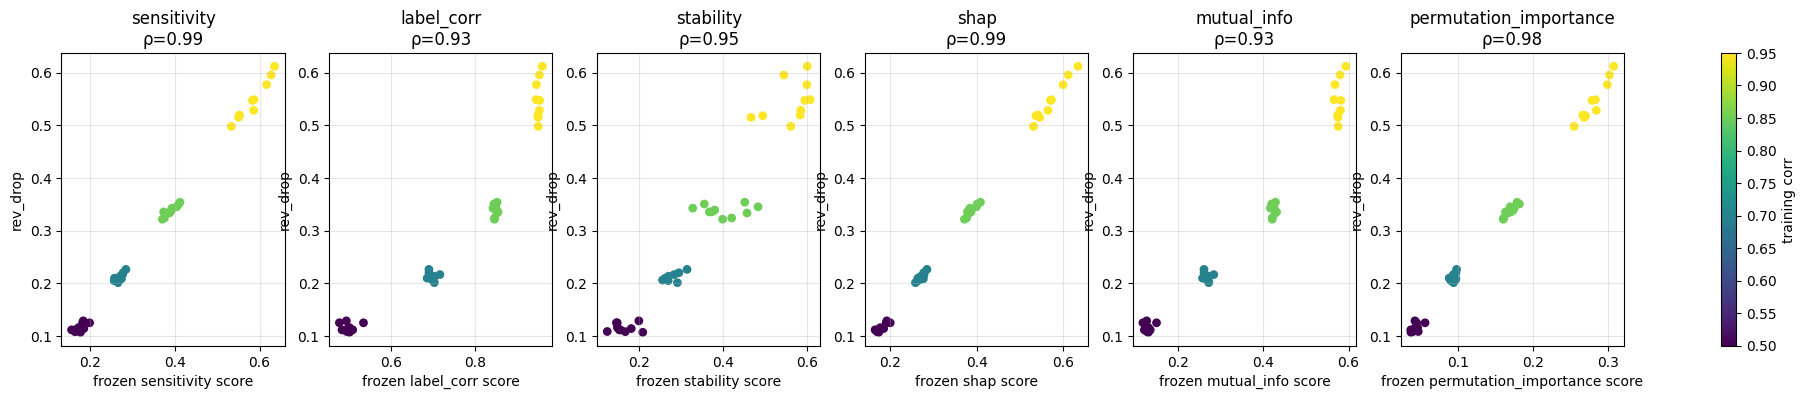


=== Score vs mean_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9851 0.9714 0.9955 0.0                  0.8821     0.0000     0.0          0.0000
            label_corr 40    0.9313 0.9090 0.9652 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9535 0.9438 0.9718 0.0                  0.6172     0.0000     0.0          0.0001
                  shap 40    0.9852 0.9713 0.9961 0.0                  0.8822     0.0000     0.0          0.0000
           mutual_info 40    0.9306 0.9090 0.9635 0.0                 -0.0816     0.6213     0.0          0.6213
permutation_importance 40    0.9698 0.9579 0.9840 0.0                  0.7545     0.0000     0.0          0.0000

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025 0.975]
Intercept       0.078    0.001  132.747  0.000   0.077  0.079
sensitivi

/tmp/ipykernel_49/2326687402.py:86: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_49/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)


In [35]:
# OOD + ANALYSIS (only after the freeze) 
ood_long, ood_wide = ood_evaluate(CONFIG)
results, controls, blind, mixed = analyze(CONFIG, target="rev_drop")
_ = analyze(CONFIG, target="mean_drop", plot=False)

## Corrections: design-based registry and shared-core export

- Spuriousness is determined from the **planned/design correlation**, not the noisy realized correlation in a finite sample.
- Convention: `abs(design_corr) > threshold`; exactly 0.50 is **not** spurious when threshold is 0.50.
- The observed sample correlation remains recorded as a diagnostic.
- The final cell writes `core.py` so downstream notebooks can import shared scoring/intervention functions. Run it before using `from core import ...`.
- These are protocol/code corrections. They do not retroactively change existing frozen runs or results; use a fresh output directory for a rerun.
- **Added baselines:** `mutual_info` (training labels vs. attribute) and `permutation_importance` (grouped attribute *shuffle* across validation examples, 5 repeats, fixed seed; not the same as `intervene()`). Both use pre-deployment data only. Because the permutation definition changed, the run directory is `runs_mi_perm_v2`; do not reuse older frozen score files.


In [36]:
# EXPORT SHARED CORE (run this cell to create core.py for later notebooks)
# Keep Notebook 0 self-contained; downstream notebooks may import this generated module.
from pathlib import Path
import textwrap

CORE_SOURCE = r"""
import numpy as np
from sklearn.metrics import accuracy_score
from itertools import combinations
from math import factorial

ATTRS = ["color", "marker_tl", "marker_br"]
PATCH = {"marker_tl": (slice(1, 4), slice(1, 4)),
         "marker_br": (slice(24, 27), slice(24, 27))}

def flat(x):
    return x.reshape(len(x), -1)

def intervene(images, attr):
    x = images.copy()
    if attr == "color":
        x[:, [0, 1]] = images[:, [1, 0]]
    elif attr in PATCH:
        r, c = PATCH[attr]
        x[:, 2, r, c] = 1.0 - images[:, 2, r, c]
    elif attr != "null":
        raise ValueError(attr)
    return x

def build_registry(labels, attrs, threshold=0.5, design_corrs=None):
    reg = {}
    for a, v in attrs.items():
        observed = float(np.corrcoef(labels, v)[0, 1])
        designed = float(design_corrs[a]) if design_corrs is not None and a in design_corrs else observed
        reg[a] = {"train_corr": observed, "design_corr": designed,
                  "spurious": abs(designed) > threshold}
    return reg

def sensitivity_score(model, X, attr):
    return float(np.mean(model.predict(flat(X)) != model.predict(flat(intervene(X, attr)))))

def label_corr_score(labels, attrs, attr):
    return abs(float(np.corrcoef(labels, attrs[attr])[0, 1]))

def stability_score(model, X, y, attrs, attr):
    pred = model.predict(flat(X))
    agree = attrs[attr] == y
    if agree.sum() < 20 or (~agree).sum() < 20:
        return np.nan
    return float(accuracy_score(y[agree], pred[agree]) -
                 accuracy_score(y[~agree], pred[~agree]))

def mutual_information_score(labels, attrs, attr):
    from sklearn.metrics import mutual_info_score
    return float(mutual_info_score(np.asarray(labels).astype(int),
                                   np.asarray(attrs[attr]).astype(int)))

def grouped_attribute_permutation_score(model, X, y, attr_values, attr, n_repeats=5, seed=12345):
    X = np.asarray(X); y = np.asarray(y)
    current = np.asarray(attr_values).astype(np.int64)
    if not (len(X) == len(y) == len(current)):
        raise ValueError("X, y and attr_values must have equal lengths.")
    if attr != "color" and attr not in PATCH:
        raise ValueError(f"Unknown attribute: {attr}")
    baseline_acc = accuracy_score(y, model.predict(flat(X)))
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(n_repeats):
        shuffled = rng.permutation(current)
        X_perm = X.copy()
        if attr == "color":
            changed = shuffled != current
            X_perm[changed, 0] = X[changed, 1]
            X_perm[changed, 1] = X[changed, 0]
        else:
            r, c = PATCH[attr]
            X_perm[:, 2, r, c] = shuffled[:, None, None].astype(X_perm.dtype)
        drops.append(baseline_acc - accuracy_score(y, model.predict(flat(X_perm))))
    return float(np.mean(drops))

def attribute_shapley(model, X, y, attr_list):
    k = len(attr_list)
    def value(S):
        x = X
        for a in S:
            x = intervene(x, a)
        proba = model.predict_proba(flat(x))
        return proba[np.arange(len(y)), y]
    cache = {frozenset(S): value(S)
             for r in range(k + 1) for S in combinations(attr_list, r)}
    phi = {}
    for a in attr_list:
        others = [b for b in attr_list if b != a]
        tot = np.zeros(len(y))
        for r in range(k):
            w = factorial(r) * factorial(k-r-1) / factorial(k)
            for S in combinations(others, r):
                tot += w * (cache[frozenset(S)] - cache[frozenset(S) | {a}])
        phi[a] = float(np.mean(np.abs(tot)))
    return phi
"""
Path("core.py").write_text(CORE_SOURCE.strip() + "\n", encoding="utf-8")
print("Wrote shared module:", Path("core.py").resolve())
print("Registry rule: spurious iff |designed correlation| > threshold.")


Wrote shared module: /kaggle/working/core.py
Registry rule: spurious iff |designed correlation| > threshold.
